In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"muhammadfaiqml","key":"6444f26246a4c519afad4f38daf48328"}'}

In [2]:
!mkdir -p ~/.kaggleD
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d tawsifurrahman/covid19-radiography-database -p /content/data --unzip

cp: cannot create regular file '/root/.kaggle/': Not a directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
100% 778M/778M [00:09<00:00, 90.3MB/s]



In [3]:
from pathlib import Path
import pandas as pd

root = Path("/content/data/COVID-19_Radiography_Dataset")
rows = [{"path": str(p), "label": c}
        for c in ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
        for p in (root / c / "images").glob("*.png")]

df = pd.DataFrame(rows)
print("DATASET CREATED :)")

DATASET CREATED :)


In [4]:
print("Class Contribution :)")
print(df["label"].value_counts())

Class Contribution :)
label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64


In [5]:
print(f"MISSING VALUES:{df.isnull().sum().to_dict()}")
import os
missing_files = 0
for path in df["path"]:
  if not os.path.exists(path):
    missing_files += 1
print("Missing Files on Disk:", missing_files)

MISSING VALUES:{'path': 0, 'label': 0}
Missing Files on Disk: 0


BCZ DATASET IS CLEAN WE ARE MOVING TOWARDS DATA PREPROESSING

In [6]:
from sklearn.model_selection import train_test_split
train_df , temp_df = train_test_split(
    df ,
    test_size    = 0.20,
    random_state = 42,
    stratify     = df["label"]
)
val_df, test_df = train_test_split(
    temp_df,
    test_size    = 0.50,
    random_state = 42,
    stratify     = temp_df['label']
)

print(f"Training set size: {len(train_df)} (80%)")
print(f"Validation set size: {len(val_df)} (10%)")
print(f"Test set size: {len(test_df)} (10%)")

Training set size: 16932 (80%)
Validation set size: 2116 (10%)
Test set size: 2117 (10%)


In [7]:
import torch
from torch.utils.data import Dataset , DataLoader
from torchvision import transforms
from    PIL import Image

BATCH_SIZE = 32


train_transform = transforms.Compose([
    transforms.Resize((224 , 244)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class COVIDDataset(Dataset):
  def __init__(self , df , transform=None):
    self.df         = df.reset_index(drop=True)
    self.transform  = transform
    self.label_map  = {"COVID": 0, "Lung_Opacity": 1, "Normal": 2, "Viral Pneumonia": 3}

  def __len__(self):
    return len(self.df)
  def __getitem__(self, idx):
    img_path   = self.df.iloc[idx]['path']
    label_name = self.df.iloc[idx]['label']
    label      = self.label_map[label_name]

    image      =  Image.open(img_path).convert("RGB")

    if self.transform:
      image = self.transform(image)
    return image , torch.tensor(label , dtype=torch.long)

train_dataset = COVIDDataset(train_df, transform=train_transform)
val_dataset = COVIDDataset(val_df, transform=val_test_transform)
test_dataset = COVIDDataset(test_df, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train Batches: {len(train_loader)}")
print(f"Validation Batches: {len(val_loader)}")
print(f"Test Batches: {len(test_loader)}")

Train Batches: 530
Validation Batches: 67
Test Batches: 67


In [8]:
import torch.nn as nn
from torchvision.models import resnet18 , ResNet18_Weights

model        = resnet18(weights=ResNet18_Weights.DEFAULT)
num_classes  = 4
model.fc     = nn.Linear(model.fc.in_features , num_classes)
device       = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model        = model.to(device)
print(f"Model Successfully moved to {device}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 56.3MB/s]


Model Successfully moved to cuda


In [9]:
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{num_epochs}]", leave=True)

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

        batch_acc = 100.0 * predicted.eq(labels).sum().item() / labels.size(0)
        loop.set_postfix(loss=f"{loss.item():.4f}", acc=f"{batch_acc:.2f}%")

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = 100.0 * correct_train / total_train

    print(f" Epoch [{epoch+1}/{num_epochs}] Completed --> Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}%\n")

Epoch [1/5]: 100%|██████████| 530/530 [01:34<00:00,  5.59it/s, acc=100.00%, loss=0.2751]


 Epoch [1/5] Completed --> Train Loss: 0.4360 | Train Acc: 84.03%



Epoch [2/5]: 100%|██████████| 530/530 [01:39<00:00,  5.35it/s, acc=100.00%, loss=0.1487]


 Epoch [2/5] Completed --> Train Loss: 0.2936 | Train Acc: 89.72%



Epoch [3/5]: 100%|██████████| 530/530 [01:30<00:00,  5.84it/s, acc=50.00%, loss=0.7606]


 Epoch [3/5] Completed --> Train Loss: 0.2549 | Train Acc: 90.89%



Epoch [4/5]: 100%|██████████| 530/530 [01:31<00:00,  5.82it/s, acc=75.00%, loss=0.9752]


 Epoch [4/5] Completed --> Train Loss: 0.2452 | Train Acc: 91.53%



Epoch [5/5]: 100%|██████████| 530/530 [01:30<00:00,  5.85it/s, acc=75.00%, loss=0.2129]

 Epoch [5/5] Completed --> Train Loss: 0.2203 | Train Acc: 92.19%



OUR MODEL IS GIVING ABOUT 92% ON ITS FIFTH EPOCH , NOW WE ARE TESTING IT ON VALIDATION DATA :)

In [10]:
model.eval()
correct_val   = 0.0
total_val     = 0
val_loss      = 0
val_loss      = 0.0
criterion_val = nn.CrossEntropyLoss()

with torch.no_grad():
  for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion_val(outputs, labels)

        val_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_val += labels.size(0)
        correct_val += predicted.eq(labels).sum().item()

final_val_loss = val_loss / len(val_loader.dataset)
final_val_acc = 100.0 * correct_val / total_val

print(f"Validation Results --> Loss: {final_val_loss:.4f} | Accuracy: {final_val_acc:.2f}%")


Validation Results --> Loss: 0.2236 | Accuracy: 91.87%


In [11]:
model.eval()
correct_test = 0
total_test = 0
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = nn.CrossEntropyLoss()(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_test += labels.size(0)
        correct_test += predicted.eq(labels).sum().item()

final_test_loss = test_loss / len(test_loader.dataset)
final_test_acc = 100.0 * correct_test / total_test

print(f"Final Test Results --< Loss: {final_test_loss:.4f} | Accuracy: {final_test_acc:.2f}%\n")


Final Test Results --< Loss: 0.2214 | Accuracy: 92.68%



In [12]:
import cv2
import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_cam(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[:, class_idx]
        self.model.zero_grad()
        score.backward(retain_graph=True)

        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224))
        if cam.max() != 0:
            cam = cam / cam.max()

        return cam, class_idx

target_layer = model.layer4[-1]
grad_cam = GradCAM(model, target_layer)

idx_to_label = {0: "COVID", 1: "Lung_Opacity", 2: "Normal", 3: "Viral Pneumonia"}
print("GradCAM initialized successfully!")

GradCAM initialized successfully!


In [14]:
img_path = test_df.iloc[0]['path']
original_image = Image.open(img_path).convert('RGB').resize((224, 224))

input_tensor = val_test_transform(original_image).unsqueeze(0).to(device)

cam, predicted_class_idx = grad_cam.generate_cam(input_tensor)
predicted_label = list({"COVID": 0, "Lung_Opacity": 1, "Normal": 2, "Viral Pneumonia": 3}.keys())[list({"COVID": 0, "Lung_Opacity": 1, "Normal": 2, "Viral Pneumonia": 3}.values()).index(predicted_class_idx)]

print(f"Model Prediction: {predicted_label}")

if predicted_label == "COVID":
    print("⚠️ COVID detected! Generating infection localization mask...")

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    original_np = np.array(original_image)
    overlay = cv2.addWeighted(original_np, 0.6, heatmap, 0.4, 0)

    plt.figure(figsize=(6, 6))
    plt.imshow(overlay)
    plt.axis('off')
    plt.title(f"Prediction: {predicted_label} (Heatmap Mask)")
    plt.show()
else:
    print(f"Prediction is {predicted_label}, so no infection mask needed.")

Model Prediction: Normal
Prediction is Normal, so no infection mask needed.


Model Prediction: COVID
⚠️ COVID detected! Generating infection localization mask...


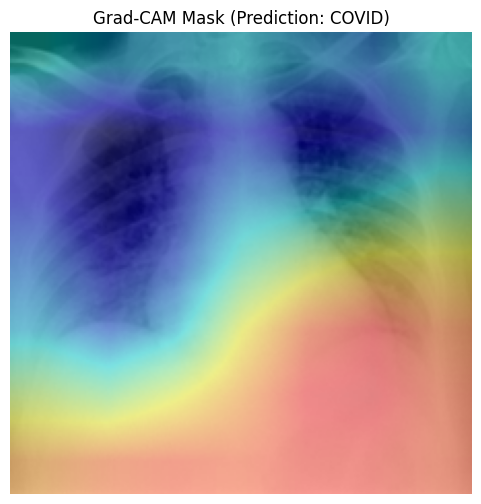

In [17]:
covid_row = test_df[test_df['label'] == 'COVID'].iloc[0]
img_path = covid_row['path']

original_image = Image.open(img_path).convert('RGB').resize((224, 224))
input_tensor = val_test_transform(original_image).unsqueeze(0).to(device)

cam, predicted_class_idx = grad_cam.generate_cam(input_tensor)
predicted_label = idx_to_label[predicted_class_idx]

print(f"Model Prediction: {predicted_label}")

if predicted_label == "COVID":
    print("COVID detected! Generating infection localization mask...")
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    original_np = np.array(original_image)
    overlay = cv2.addWeighted(original_np, 0.6, heatmap, 0.4, 0)

    plt.figure(figsize=(6, 6))
    plt.imshow(overlay)
    plt.axis('off')
    plt.title(f"Grad-CAM Mask (Prediction: {predicted_label})")
    plt.show()